# Lab: Relationships Between Quantitative Features

Use a historical mammal sleep dataset to compare dreaming, non-dreaming, and total sleep. Use non-dreaming versus total sleep as the main model, then examine whether danger and predation ratings add information. Finally, investigate the nonlinear pattern between gestation time and total sleep.

Support conclusions with the plots and calculations. Explain how well a straight line follows the points and how much variation remains.

## Learning goals

- Describe whether points trend upward or downward, follow a straight or curved pattern, cluster closely around that pattern, or include unusual observations.
- Calculate correlation and interpret R-squared on the correct response scale.
- Recognize nonlinear patterns and compare original gestation with log-transformed gestation.
- Examine additional categorical features visually and compare model R-squared on the same observations.
- Check missing codes, units, category counts, and transformations.
- Distinguish improved fit to observed records from causation and performance on new data.

## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can answer it?
3. **Evidence:** What should we calculate and display?
4. **Check:** Does the result make sense in context and agree with the original records?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete each investigation in order. Use separate cells for individual operations and add cells as needed. Give figures informative titles, named colors, and axis labels with units or transformations. Use the default point transparency and line widths. `ci=None` can omit confidence bands so the patterns and group lines are easier to compare.

## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the code and checking every claim against the source and your output. Complete the AI-use reflection at the end.

## Dataset and context

Use the [StatLib mammal sleep data hosted by UC Berkeley](https://www.stat.berkeley.edu/~spector/s100/data/sleep.dat) and its [measurement dictionary](https://www.stat.berkeley.edu/~spector/s100/data/sleep.html). A local copy is supplied as `data/mammal_sleep.csv`.

The supplied `data/mammal_sleep.csv` contains all 62 records and 11 features, including species names and both sleep phases. One row describes a mammal species, not an individual animal or a night. The data trace to Allison and Cicchetti's 1976 study, [Sleep in mammals: ecological and constitutional correlates](https://pubmed.ncbi.nlm.nih.gov/982039/). This is a historical comparative dataset, not a random sample of all mammals; individual collection dates are not supplied.

Course preparation preserves all values and names, gives columns descriptive names, and converts the source's `-999` missing code into blank CSV fields. Use ordinary `pd.read_csv()`; blanks are recognized as missing. The terms dreaming and non-dreaming identify the study's sleep-phase measurements; they are not direct reports of an animal's subjective dream experiences.

### Data dictionary

| Feature | Meaning and units or codes |
| --- | --- |
| `species` | Species label as recorded in the historical source |
| `non_dreaming_sleep` | Non-dreaming sleep in hours per day |
| `dreaming_sleep` | Dreaming sleep in hours per day |
| `body_weight` | Body weight in kilograms |
| `brain_weight` | Brain weight in grams |
| `max_life_span` | Maximum lifespan in years |
| `gestation_time` | Gestation duration in days |
| `predation_index` | Ordered rating, 1–5: lower to higher likelihood of being preyed upon |
| `sleep_exposure_index` | Ordered rating, 1–5: more protected to more exposed sleeping conditions |
| `danger_index` | Ordered rating, 1–5: lower to higher overall danger from other animals |
| `total_sleep` | Total sleep in hours per day; sum of the two phases |

The indices are **ordinal categorical features**, even though stored as numbers. A one-point difference is not a documented equal increment of physical risk. Overall danger incorporates predation, sleep exposure, and other information, so these ratings are not independent measurements. In our models, represent rating levels as categories rather than assuming equal numerical spacing.

## Load and inspect the data

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
mammals_df = pd.read_csv("data/mammal_sleep.csv")

In [6]:
display(mammals_df.head())

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
0,African elephant,6654.000,5712.0,NaN,NaN,3.3,38.6,645.0,3,5,3
1,African giant pouched rat,1.000,6.6,6.3,2.0,8.3,4.5,42.0,3,1,3
2,Arctic Fox,3.385,44.5,NaN,NaN,12.5,14.0,60.0,1,1,1
3,Arctic ground squirrel,0.920,5.7,NaN,NaN,16.5,NaN,25.0,5,2,3
4,Asian elephant,2547.000,4603.0,2.1,1.8,3.9,69.0,624.0,3,5,4


In [7]:
display(mammals_df.tail())

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
57,Tree hyrax,2.000,12.3,4.9,0.5,5.4,7.5,200.0,3,1,3
58,Tree shrew,0.104,2.5,13.2,2.6,15.8,2.3,46.0,3,2,2
59,Vervet,4.190,58.0,9.7,0.6,10.3,24.0,210.0,4,3,4
60,Water opossum,3.500,3.9,12.8,6.6,19.4,3.0,14.0,2,1,1
61,Yellow-bellied marmot,4.050,17.0,NaN,NaN,NaN,13.0,38.0,3,1,1


In [8]:
print(mammals_df.shape)

(62, 11)


In [9]:
mammals_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   species               62 non-null     object 
 1   body_weight           62 non-null     float64
 2   brain_weight          62 non-null     float64
 3   non_dreaming_sleep    48 non-null     float64
 4   dreaming_sleep        50 non-null     float64
 5   total_sleep           58 non-null     float64
 6   max_life_span         58 non-null     float64
 7   gestation_time        58 non-null     float64
 8   predation_index       62 non-null     int64  
 9   sleep_exposure_index  62 non-null     int64  
 10  danger_index          62 non-null     int64  
dtypes: float64(7), int64(3), object(1)
memory usage: 5.5+ KB


In [10]:
display(mammals_df.isnull().sum())

species                  0
body_weight              0
brain_weight             0
non_dreaming_sleep      14
dreaming_sleep          12
total_sleep              4
max_life_span            4
gestation_time           4
predation_index          0
sleep_exposure_index     0
danger_index             0
dtype: int64

**What does one row represent?**

Your answer: One row represents a single mammal species included in the Allison and Cicchetti (1976) study.

**Complete the table using the data dictionary, `.info()`, and `.isnull().sum()`. For data type, use categorical or quantitative. For data storage type, report the Pandas dtype. For missing values, report the count, including 0 when none are missing.**

| Feature | Data type | Data storage type | Missing values |
| --- | --- | --- | ---: |
| `species` | Categorical | object | 0 |
| `non_dreaming_sleep` | Quantitative | float64 | 14 |
| `dreaming_sleep` | Quantitative | float64 | 12 |
| `body_weight` |Quantitative  | float64 | 0 |
| `brain_weight` | Quantitative |float64  | 0 |
| `max_life_span` | Quantitative | float64 | 4 |
| `gestation_time` |Quantitative  | float64 | 4 |
| `predation_index` | Categorical | int64 | 0 |
| `sleep_exposure_index` | Categorical | int64 | 0 |
| `danger_index` | Categorical | int64 | 0 |
| `total_sleep` | Categorical | float64 | 4 |

Your answer: The dataset contains 62 mammal species and 11 features. Most measurements are quantitative numerical variables stored as either float64 or int64

# Investigation 1: Dreaming, non-dreaming, and total sleep

## Step 1: Question

**How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep?**

Compare three relationships in hours per day: dreaming versus non-dreaming, dreaming versus total, and non-dreaming versus total. In the last comparison, use non-dreaming sleep on the horizontal axis and total sleep as the response. This is the main model for Investigation 2.

**Predict the direction and strength of each relationship. Which phase do you expect to be more strongly related to total sleep, and why?**

Your answer: I expect all three relationships to be positive because mammals that spend more time sleeping overall are likely to spend more time in both dreaming and non-dreaming sleep. I predict that dreaming sleep versus non-dreaming sleep will show a moderate positive relationship, since species with more dreaming sleep may also tend to have more non-dreaming sleep.

## Step 2: Data

Create `sleep_df` from records complete for `dreaming_sleep`, `non_dreaming_sleep`, `total_sleep`, `danger_index`, and `predation_index`. Use `.copy()` and keep `mammals_df` unchanged. Use this same subset in all three comparisons and in Investigation 2. How many records were removed from the dataset?

Check that sleep measurements are between 0 and 24 hours per day.

In [11]:
sleep_df = mammals_df.dropna(
    subset=[
        "dreaming_sleep",
        "non_dreaming_sleep",
        "total_sleep",
        "danger_index",
        "predation_index"
    ]
).copy()

print("Original records:", len(mammals_df))
print("Records in sleep_df:", len(sleep_df))
print("Records removed:", len(mammals_df) - len(sleep_df))

Original records: 62
Records in sleep_df: 48
Records removed: 14


## Step 3: Evidence

Create three labeled regression plots with `sns.regplot()`: non-dreaming sleep versus dreaming sleep, total sleep versus dreaming sleep, and total sleep versus non-dreaming sleep. In each description, the feature after “versus” goes on the horizontal axis. Calculate the correlation and simple-line R-squared for each pair. Describe the points before relying on the fitted line.

When describing a scatterplot:

- **Direction:** Do the points generally rise or fall from left to right?
- **Form:** Does the overall pattern look roughly straight, curved, or have no clear shape? This describes the arrangement of the points, not the line drawn by the plotting function.
- **Strength:** How closely do the points follow that pattern?
- **Unusual observations:** Which points are far from most of the others?

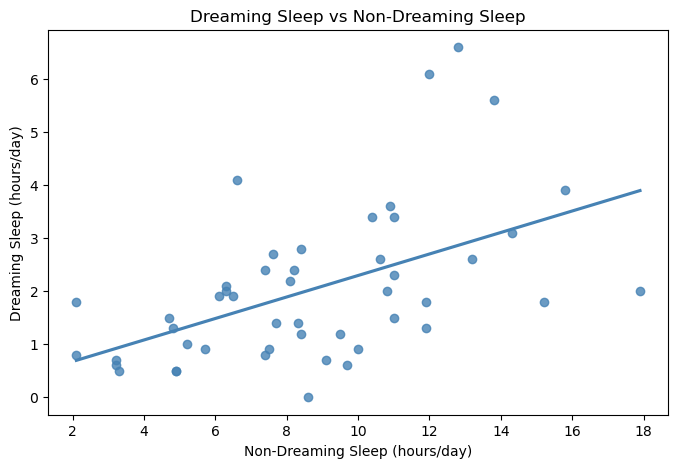

In [13]:
plt.figure(figsize=(8,5))
sns.regplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="dreaming_sleep",
    color="steelblue",
    ci=None
)
plt.title("Dreaming Sleep vs Non-Dreaming Sleep")
plt.xlabel("Non-Dreaming Sleep (hours/day)")
plt.ylabel("Dreaming Sleep (hours/day)")
plt.show()

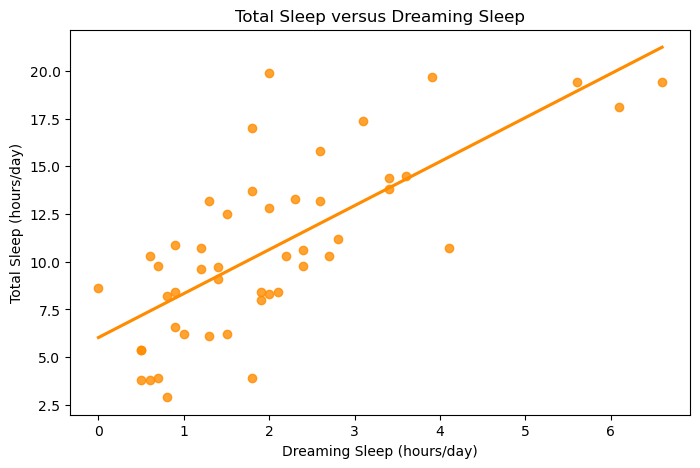

In [14]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=sleep_df,
    x="dreaming_sleep",
    y="total_sleep",
    color="darkorange",
    ci=None
)

plt.title("Total Sleep versus Dreaming Sleep")
plt.xlabel("Dreaming Sleep (hours/day)")
plt.ylabel("Total Sleep (hours/day)")
plt.show()

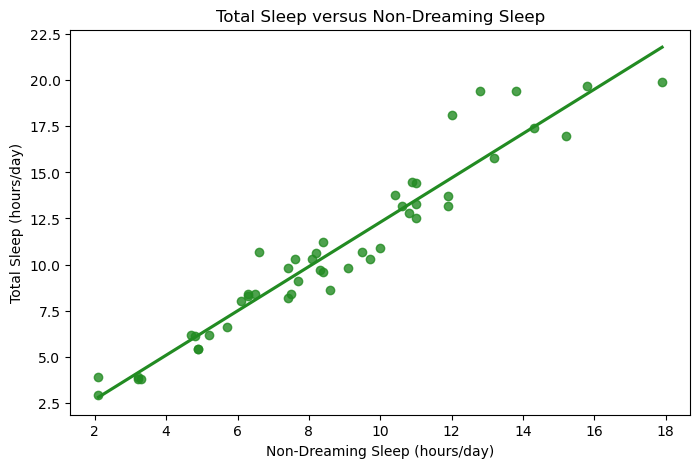

In [15]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    color="forestgreen",
    ci=None
)

plt.title("Total Sleep versus Non-Dreaming Sleep")
plt.xlabel("Non-Dreaming Sleep (hours/day)")
plt.ylabel("Total Sleep (hours/day)")
plt.show()

In [16]:
r1 = sleep_df["non_dreaming_sleep"].corr(
    sleep_df["dreaming_sleep"]
)

print("Dreaming sleep versus non-dreaming sleep")
print("r =", round(r1, 4))
print("R² =", round(r1**2, 4))
print()

# Total sleep versus dreaming sleep
r2 = sleep_df["dreaming_sleep"].corr(
    sleep_df["total_sleep"]
)

print("Total sleep versus dreaming sleep")
print("r =", round(r2, 4))
print("R² =", round(r2**2, 4))
print()

# Total sleep versus non-dreaming sleep
r3 = sleep_df["non_dreaming_sleep"].corr(
    sleep_df["total_sleep"]
)

print("Total sleep versus non-dreaming sleep")
print("r =", round(r3, 4))
print("R² =", round(r3**2, 4))

Dreaming sleep versus non-dreaming sleep
r = 0.5143
R² = 0.2645

Total sleep versus dreaming sleep
r = 0.7271
R² = 0.5287

Total sleep versus non-dreaming sleep
r = 0.9627
R² = 0.9268


**For each plot, do the points generally rise or fall? Is their pattern roughly straight or curved, and how closely do they follow it? Identify any unusual observations. Which plot is best summarized by a straight line? Explain what its R-squared tells you about total sleep.**

Your answer: In all three scatterplots, the points generally rise from left to right, indicating positive relationships between the variables. The relationship between dreaming sleep and non-dreaming sleep is positive but only moderately strong. The points follow a roughly straight pattern, but there is considerable scatter around the trend line. This is reflected by a correlation of r = 0.5143 and R² = 0.2645, meaning only about 26.5% of the variation in dreaming sleep is associated with a linear relationship with non-dreaming sleep.

## Step 4: Check

Check that `dreaming_sleep + non_dreaming_sleep` agrees with `total_sleep` using `np.isclose()`, which allows for ordinary floating-point rounding. Display several original rows with their phase sum. Then display the three records with the longest non-dreaming sleep and locate their points on the non-dreaming versus total sleep plot. Do the plotted values agree with the records?

In [19]:
sleep_df["phase_sum"] = (
    sleep_df["dreaming_sleep"]
    + sleep_df["non_dreaming_sleep"]
)

phase_matches = np.isclose(
    sleep_df["phase_sum"],
    sleep_df["total_sleep"]
)

print("All phase sums match total_sleep:",
      phase_matches.all())


display(
    sleep_df[
        [
            "species",
            "dreaming_sleep",
            "non_dreaming_sleep",
            "phase_sum",
            "total_sleep"
        ]
    ].head(10)
)

display(
    sleep_df.nlargest(
        3,
        "non_dreaming_sleep"
    )[
        [
            "species",
            "non_dreaming_sleep",
            "dreaming_sleep",
            "phase_sum",
            "total_sleep"
        ]
    ]
)

All phase sums match total_sleep: True


,species,dreaming_sleep,non_dreaming_sleep,phase_sum,total_sleep
1,African giant pouched rat,2.0,6.3,8.3,8.3
4,Asian elephant,1.8,2.1,3.9,3.9
5,Baboon,0.7,9.1,9.8,9.8
6,Big brown bat,3.9,15.8,19.7,19.7
7,Brazilian tapir,1.0,5.2,6.2,6.2
8,Cat,3.6,10.9,14.5,14.5
9,Chimpanzee,1.4,8.3,9.7,9.7
10,Chinchilla,1.5,11.0,12.5,12.5
11,Cow,0.7,3.2,3.9,3.9
12,Desert hedgehog,2.7,7.6,10.3,10.3


,species,non_dreaming_sleep,dreaming_sleep,phase_sum,total_sleep
32,Little brown bat,17.9,2.0,19.9,19.9
6,Big brown bat,15.8,3.9,19.7,19.7
41,Owl monkey,15.2,1.8,17.0,17.0


In [20]:
longest_sleep = sleep_df.nlargest(
    3,
    "non_dreaming_sleep"
)

display(
    longest_sleep[
        [
            "species",
            "non_dreaming_sleep",
            "dreaming_sleep",
            "total_sleep"
        ]
    ]
)

,species,non_dreaming_sleep,dreaming_sleep,total_sleep
32,Little brown bat,17.9,2.0,19.9
6,Big brown bat,15.8,3.9,19.7
41,Owl monkey,15.2,1.8,17.0


## Step 5: Conclusion

**Research question:** How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep? Mammals that spend more time in dreaming sleep generally also tend to spend more time in non-dreaming sleep, but the relationship is only moderate. The correlation between dreaming sleep and non-dreaming sleep was r = 0.5143, with R² = 0.2645, indicating that about 26.5% of the variation is explained by a linear relationship.

**Do mammals that spend more time in dreaming sleep also tend to spend more time in non-dreaming sleep? Which phase is more strongly related to total sleep? Support your answers with the plots, correlations, and R-squared values. Did the results match your prediction?**

Your answer: Yes, mammals that spend more time in dreaming sleep generally also tend to spend more time in non-dreaming sleep, but the relationship is only moderate. The scatterplot showed an upward trend, and the correlation between dreaming sleep and non-dreaming sleep was r = 0.5143 with an R² = 0.2645.

## Step 6: Limitation

**State two limitations specific to these sleep relationships. Explain why a stronger correlation is not automatically a better scientific explanation.**

Your answer: One limitation is that the dataset contains only 62 mammal species and is a historical comparative dataset rather than a random sample of all mammals. Therefore, the observed relationships may not represent all mammal species.

# Investigation 2: Do danger and predation add information?

## Step 1: Question

**Do danger and predation categories add information about total sleep beyond non-dreaming sleep?** 

**Predict whether each index will add substantial, small, or little visible information. What would you look for at comparable non-dreaming-sleep durations?**

Your answer: I predict that both danger and predation ratings will add some information about total sleep, but the effect will likely be smaller than the effect of non-dreaming sleep. Since non-dreaming sleep already has a very strong relationship with total sleep (R² = 0.9268), there may be limited variation left for the danger and predation categories to explain.

## Step 2: Data

Reuse `sleep_df` and its original sleep measurements. Count records for each danger and predation rating and display a cross-tabulation of the two indices. Keep all five original levels in their natural order. Higher predation index values mean a mammal is more likely to be preyed upon. Higher danger index values mean greater overall danger from other animals.

In [21]:
print("Danger Index Counts")
display(
    sleep_df["danger_index"]
    .value_counts()
    .sort_index()
)

print("Predation Index Counts")
display(
    sleep_df["predation_index"]
    .value_counts()
    .sort_index()
)

Danger Index Counts


danger_index
1    14
2    12
3     8
4     9
5     5
Name: count, dtype: int64

Predation Index Counts


predation_index
1    10
2    13
3     9
4     7
5     9
Name: count, dtype: int64

In [22]:
print("Danger vs Predation Cross-Tabulation")
display(
    pd.crosstab(
        sleep_df["danger_index"],
        sleep_df["predation_index"]
    )
)

Danger vs Predation Cross-Tabulation


predation_index,1,2,3,4,5
danger_index,,,,,
1,10,4,0,0,0
2,0,9,3,0,0
3,0,0,5,2,1
4,0,0,1,5,3
5,0,0,0,0,5


## Step 3: Evidence

Use `sns.lmplot()` twice on the non-dreaming–total sleep relationship, once colored by `danger_index` and once by `predation_index`. Set `hue_order=[1, 2, 3, 4, 5]`, use a named palette, and label the legend so the index direction is clear. The separate lines show group patterns; small groups may produce unstable lines. Compare groups where their non-dreaming-sleep ranges overlap.

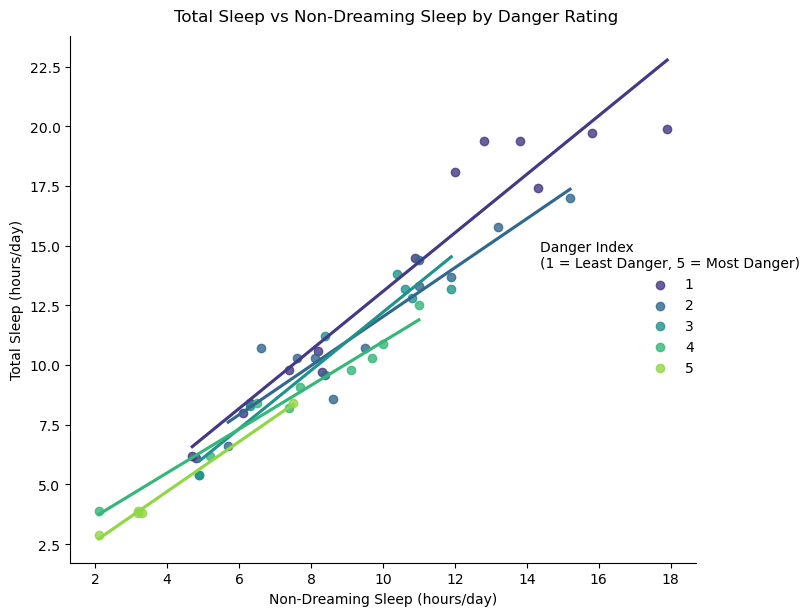

In [23]:
danger_plot = sns.lmplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    hue="danger_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="viridis",
    ci=None,
    height=6,
    aspect=1.2
)

danger_plot.set_axis_labels(
    "Non-Dreaming Sleep (hours/day)",
    "Total Sleep (hours/day)"
)

danger_plot.fig.suptitle(
    "Total Sleep vs Non-Dreaming Sleep by Danger Rating",
    y=1.02
)

danger_plot._legend.set_title(
    "Danger Index\n(1 = Least Danger, 5 = Most Danger)"
)

plt.show()

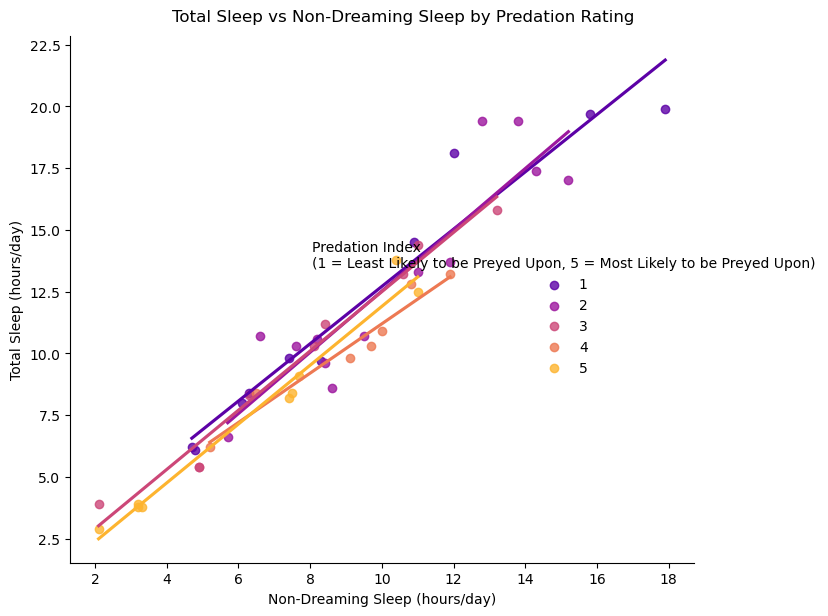

In [24]:
predation_plot = sns.lmplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    hue="predation_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="plasma",
    ci=None,
    height=6,
    aspect=1.2
)

predation_plot.set_axis_labels(
    "Non-Dreaming Sleep (hours/day)",
    "Total Sleep (hours/day)"
)

predation_plot.fig.suptitle(
    "Total Sleep vs Non-Dreaming Sleep by Predation Rating",
    y=1.02
)

predation_plot._legend.set_title(
    "Predation Index\n(1 = Least Likely to be Preyed Upon, 5 = Most Likely to be Preyed Upon)"
)

plt.show()

**Describe overlap and separation in each plot. How do the group sizes and available non-dreaming-sleep ranges affect your interpretation?**

Your answer: In both plots, there is considerable overlap among the danger and predation groups. All groups show a positive relationship between non-dreaming sleep and total sleep, which is consistent with the strong overall relationship found in Investigation 1. The regression lines generally follow similar upward trends, suggesting that non-dreaming sleep remains the primary factor associated with total sleep.

### Compare model R-squared

The supplied helper follows the lecture's least-squares calculation. Read and run it; you do not need to recreate its matrix operations. `pd.get_dummies()` represents each rating with category indicators. `drop_first=True` chooses a reference level. This avoids assuming equal distances between index values.

These are **additive models**: one shared slope for the quantitative predictor and category-specific intercept adjustments. They differ from the separate group slopes in `lmplot()`. Compare the baseline, baseline plus danger, baseline plus predation, and baseline plus both, all on identical rows and the same response scale. Training R-squared cannot decrease when predictors are added to these nested models; an increase alone does not establish improved performance on new observations.

In [26]:
def calculate_r_squared(data, predictor, response, categorical_features):
    predictors = pd.get_dummies(
        data[[predictor, *categorical_features]],
        columns=categorical_features, drop_first=True, dtype=float
    )
    predictors.insert(0, "intercept", 1.0)
    x = predictors.to_numpy(dtype=float)
    y = data[response].to_numpy(dtype=float)
    fitted = x @ np.linalg.lstsq(x, y, rcond=None)[0]
    return 1 - ((y - fitted) ** 2).sum() / ((y - y.mean()) ** 2).sum()

In [27]:
phase_comparison = pd.DataFrame({
    "Model": [
        "Non-dreaming Sleep Only",
        "Non-dreaming + Danger",
        "Non-dreaming + Predation",
        "Non-dreaming + Danger + Predation"
    ],
    "R_squared": [
        calculate_r_squared(
            sleep_df,
            "non_dreaming_sleep",
            "total_sleep",
            []
        ),
        calculate_r_squared(
            sleep_df,
            "non_dreaming_sleep",
            "total_sleep",
            ["danger_index"]
        ),
        calculate_r_squared(
            sleep_df,
            "non_dreaming_sleep",
            "total_sleep",
            ["predation_index"]
        ),
        calculate_r_squared(
            sleep_df,
            "non_dreaming_sleep",
            "total_sleep",
            ["danger_index", "predation_index"]
        )
    ]
})

display(phase_comparison)

,Model,R_squared
0,Non-dreaming Sleep Only,0.926820
1,Non-dreaming + Danger,0.942657
2,Non-dreaming + Predation,0.937084
3,Non-dreaming + Danger + Predation,0.951454


## Step 4: Check

For each danger rating, display the smallest and largest non-dreaming sleep values using `.groupby()` and `.agg(["min", "max"])`. Repeat for predation ratings.

Compare these ranges with the group plots. Use the ranges to identify where two groups actually have observations at similar non-dreaming sleep durations.

In [28]:
danger_ranges = (
    sleep_df.groupby("danger_index")["non_dreaming_sleep"]
    .agg(["min", "max"])
)

print("Danger Index Ranges")
display(danger_ranges)

predation_ranges = (
    sleep_df.groupby("predation_index")["non_dreaming_sleep"]
    .agg(["min", "max"])
)

print("Predation Index Ranges")
display(predation_ranges)

Danger Index Ranges


,min,max
danger_index,,
1,4.7,17.9
2,5.7,15.2
3,4.9,11.9
4,2.1,11.0
5,2.1,7.5


Predation Index Ranges


,min,max
predation_index,,
1,4.7,17.9
2,5.7,15.2
3,2.1,13.2
4,5.2,11.9
5,2.1,11.0


**Choose two danger groups. Over what range of non-dreaming sleep do both groups have observations? Why should you compare their lines within that shared range?**

Your answer: Danger group 1 has non-dreaming sleep values ranging from 4.7 to 17.9 hours, while danger group 2 ranges from 5.7 to 15.2 hours. Therefore, both groups have observations in the shared range of 5.7 to 15.2 hours of non-dreaming sleep.

## Step 5: Conclusion

**Research question:** Do danger and predation categories add information about total sleep beyond non-dreaming sleep?

**Does adding danger, predation, or both improve the model of total sleep? Report the four R-squared values and how much each changes from non-dreaming sleep alone. Are the improvements small or large? Explain how the group plots support your answer.**

Your answer: Yes, adding danger, predation, or both improved the model of total sleep, but the improvements were relatively small because the baseline model already explained most of the variation in total sleep.

## Step 6: Limitation

**Identify two limitations of this investigation.**

Your answer: One limitation of this investigation is that some danger and predation categories contain relatively few species and cover different ranges of non-dreaming sleep. Small group sizes can make the fitted regression lines unstable and more sensitive to individual observations.

A second limitation is that the danger and predation ratings are ordinal categories based on expert assessments rather than direct physical measurements. In addition, the overall danger index incorporates information related to predation and other factors, so the variables are not completely independent of one another.

# Investigation 3: Gestation time and total sleep

## Step 1: Question

**How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time?**

Gestation time is the length of a pregnancy, measured in days. We will compare it with total sleep, measured in hours per day, and see whether taking the logarithm of gestation time makes the pattern look straighter.

**Do you expect mammals with longer pregnancies to sleep more hours per day, fewer hours, or about the same amount? Explain your initial guess. You do not need prior knowledge about mammals; you will compare your prediction with the data.**

Your answer: I predict that mammals with longer gestation times will tend to sleep fewer hours per day. My reasoning is that mammals with longer pregnancies are often larger and develop more slowly, and many large mammals in the dataset appear to sleep relatively little. Therefore, I expect a negative relationship between gestation time and total sleep.

## Step 2: Data

Create `gestation_df` by dropping rows missing `gestation_time`, `total_sleep`, `danger_index`, or `predation_index`, then copying the result. How many records were removed from the dataset? Do not drop rows merely because maximum lifespan is missing. Check that gestation is positive and sleep is between 0 and 24 hours per day. Create `log10_gestation_time` only after checking the inputs.

In [39]:
gestation_df["log10_gestation_time"] = np.log10(
    gestation_df["gestation_time"]
)
r_original = gestation_df["gestation_time"].corr(
    gestation_df["total_sleep"]
)

r_log = gestation_df["log10_gestation_time"].corr(
    gestation_df["total_sleep"]
)

print("Original gestation")
print("r =", round(r_original, 4))
print("R² =", round(r_original**2, 4))

print()

print("Log10 gestation")
print("r =", round(r_log, 4))
print("R² =", round(r_log**2, 4))

Original gestation
r = -0.6313
R² = 0.3986

Log10 gestation
r = -0.6637
R² = 0.4404


## Step 3: Evidence

Plot sleep against gestation on original scales, then against log10 gestation, leaving sleep in hours per day. Calculate correlation and simple-line R-squared for each. These R-squared values share the same response scale and observations. Compare whether the points follow a straight or curved pattern and how widely they are scattered, as well as the numerical summaries.

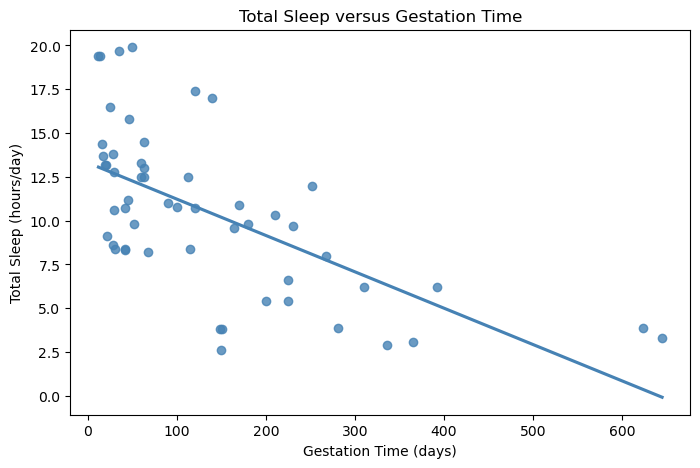

In [40]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=gestation_df,
    x="gestation_time",
    y="total_sleep",
    color="steelblue",
    ci=None
)

plt.title("Total Sleep versus Gestation Time")
plt.xlabel("Gestation Time (days)")
plt.ylabel("Total Sleep (hours/day)")

plt.show()

In [42]:
r_original = gestation_df["gestation_time"].corr(
    gestation_df["total_sleep"]
)

r_log = gestation_df["log10_gestation_time"].corr(
    gestation_df["total_sleep"]
)

print("Original gestation")
print("r =", round(r_original, 4))
print("R² =", round(r_original**2, 4))

print()

print("Log10 gestation")
print("r =", round(r_log, 4))
print("R² =", round(r_log**2, 4))

Original gestation
r = -0.6313
R² = 0.3986

Log10 gestation
r = -0.6637
R² = 0.4404


In [43]:
gestation_df["log10_gestation_time"] = np.log10(
    gestation_df["gestation_time"]
)

r_original = gestation_df["gestation_time"].corr(
    gestation_df["total_sleep"]
)

r_log = gestation_df["log10_gestation_time"].corr(
    gestation_df["total_sleep"]
)

print("Original Gestation Time")
print("Correlation (r):", round(r_original, 4))
print("R-squared:", round(r_original**2, 4))
print()

print("Log10 Gestation Time")
print("Correlation (r):", round(r_log, 4))
print("R-squared:", round(r_log**2, 4))

Original Gestation Time
Correlation (r): -0.6313
R-squared: 0.3986

Log10 Gestation Time
Correlation (r): -0.6637
R-squared: 0.4404


**What changes when gestation is log-transformed? Does the transformation remove the scatter or only improve the straight-line summary modestly?**

Your answer: The relationship between gestation time and total sleep is negative on both scales, meaning that mammals with longer gestation periods tend to sleep fewer hours per day. On the original scale, the points show a noticeable downward trend but also some curvature and considerable scatter. The correlation is r = -0.6313 and the simple-line R² = 0.3986, indicating that about 39.9% of the variation in total sleep is explained by a linear relationship with gestation time.

Reuse the group-plot and model-comparison approach from Investigation 2, now using `log10_gestation_time` as the predictor and `total_sleep` as the response. Count observations at each rating level in this subset before interpreting the group lines. Examine danger and predation separately, then compare all four additive models on `gestation_df`.

In [45]:
print("Danger Index Counts")

display(
    gestation_df["danger_index"]
        .value_counts()
        .sort_index()
)

print("Predation Index Counts")

display(
    gestation_df["predation_index"]
        .value_counts()
        .sort_index()
)

Danger Index Counts


danger_index
1    16
2    12
3    10
4     9
5     7
Name: count, dtype: int64

Predation Index Counts


predation_index
1    12
2    14
3     9
4     7
5    12
Name: count, dtype: int64

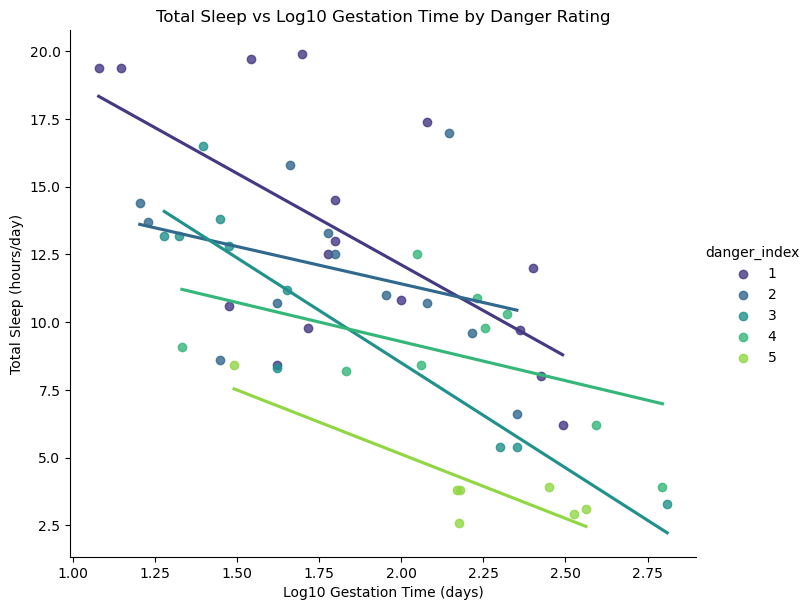

In [46]:
sns.lmplot(
    data=gestation_df,
    x="log10_gestation_time",
    y="total_sleep",
    hue="danger_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="viridis",
    ci=None,
    height=6,
    aspect=1.2
)

plt.title("Total Sleep vs Log10 Gestation Time by Danger Rating")
plt.xlabel("Log10 Gestation Time (days)")
plt.ylabel("Total Sleep (hours/day)")
plt.show()

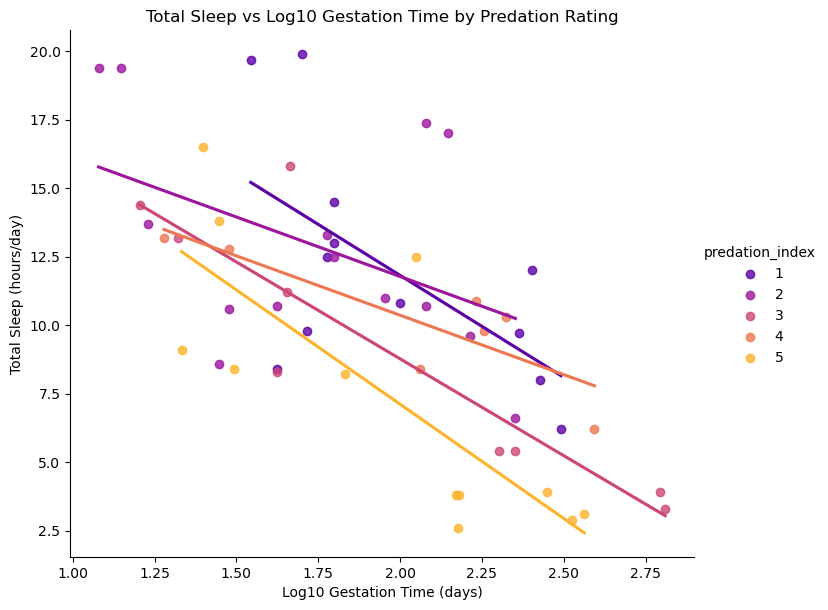

In [47]:
sns.lmplot(
    data=gestation_df,
    x="log10_gestation_time",
    y="total_sleep",
    hue="predation_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="plasma",
    ci=None,
    height=6,
    aspect=1.2
)

plt.title("Total Sleep vs Log10 Gestation Time by Predation Rating")
plt.xlabel("Log10 Gestation Time (days)")
plt.ylabel("Total Sleep (hours/day)")
plt.show()

In [48]:
sleep_comparison = pd.DataFrame({
    "Model": [
        "Log Gestation Only",
        "Log Gestation + Danger",
        "Log Gestation + Predation",
        "Log Gestation + Danger + Predation"
    ],
    "R_squared": [
        calculate_r_squared(
            gestation_df,
            "log10_gestation_time",
            "total_sleep",
            []
        ),
        calculate_r_squared(
            gestation_df,
            "log10_gestation_time",
            "total_sleep",
            ["danger_index"]
        ),
        calculate_r_squared(
            gestation_df,
            "log10_gestation_time",
            "total_sleep",
            ["predation_index"]
        ),
        calculate_r_squared(
            gestation_df,
            "log10_gestation_time",
            "total_sleep",
            ["danger_index", "predation_index"]
        )
    ]
})

display(sleep_comparison)

,Model,R_squared
0,Log Gestation Only,0.440439
1,Log Gestation + Danger,0.654154
2,Log Gestation + Predation,0.591677
3,Log Gestation + Danger + Predation,0.694263


## Step 4: Check

For the first five records, display gestation time, its logarithm, and `10 ** log10_gestation_time`. Does reversing the logarithm recover the original number of days?

Display the records with the shortest and longest gestation times. Find their points in both plots and compare the recorded sleep hours with their vertical positions. The horizontal positions change when gestation is transformed; the sleep measurements stay the same.

In [49]:
check_df = gestation_df[
    ["gestation_time", "log10_gestation_time"]
].head().copy()

check_df["recovered_gestation"] = (
    10 ** check_df["log10_gestation_time"]
)

display(check_df)


,gestation_time,log10_gestation_time,recovered_gestation
0,645.0,2.809560,645.0
1,42.0,1.623249,42.0
2,60.0,1.778151,60.0
3,25.0,1.397940,25.0
4,624.0,2.795185,624.0


In [50]:
print("Shortest gestation time")

display(
    gestation_df.nsmallest(
        1,
        "gestation_time"
    )[
        [
            "species",
            "gestation_time",
            "total_sleep",
            "log10_gestation_time"
        ]
    ]
)

print("Longest gestation time")

display(
    gestation_df.nlargest(
        1,
        "gestation_time"
    )[
        [
            "species",
            "gestation_time",
            "total_sleep",
            "log10_gestation_time"
        ]
    ]
)


Shortest gestation time


,species,gestation_time,total_sleep,log10_gestation_time
38,N. American opossum,12.0,19.4,1.079181


Longest gestation time


,species,gestation_time,total_sleep,log10_gestation_time
0,African elephant,645.0,3.3,2.80956


**Did reversing the logarithm recover the original gestation times? For the shortest and longest gestation records, do both plots show the recorded total sleep values? Describe what changed between the plots and what stayed the same.**

Your answer: Yes, reversing the logarithm recovered the original gestation times, aside from very small rounding differences caused by floating-point arithmetic. The values of 10 ** log10_gestation_time matched the original gestation times, confirming that the log transformation was applied correctly.

## Step 5: Conclusion

**Research question:** How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time?

**Do mammals with longer gestation times tend to sleep more or less? Does using log gestation make the pattern look straighter? Do danger and predation add information? Support your answers with the plots, correlation, and R-squared values, and compare the results with your prediction.**

Your answer: Mammals with longer gestation times tend to sleep less, not more. Both scatterplots showed a negative relationship between gestation time and total sleep, meaning that species with longer pregnancies generally had fewer hours of sleep per day. On the original scale, the correlation was r = -0.6313 with R² = 0.3986, indicating that about 39.9% of the variation in total sleep was explained by a linear relationship with gestation time.

## Step 6: Limitation

**Identify two limitations of the gestation and sleep investigation.**

Your answer: One limitation is that gestation time explains only part of the variation in sleep. Even after the log transformation, the model had an R² of 0.4404, meaning that about 56% of the variation in total sleep remained unexplained. Other biological and ecological factors likely influence sleep duration.

A second limitation is that this dataset contains measurements from only 58 species with complete gestation and sleep data and represents a historical comparative study rather than a random sample of all mammals. Therefore, the observed relationships may not generalize to all mammal species.

## AI-use reflection

**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:No

## Submission checklist

- Use the supplied CSV with a relative path.
- Complete the dictionary table and every written response.
- Include a prediction and all six workflow steps for each investigation.
- Include all three sleep comparison plots, two non-dreaming–total group plots, original and log-gestation sleep plots, and two sleep group plots.
- Keep observations consistent within each comparison; report counts and investigate exclusions.
- Interpret correlation and R-squared on the correct scale, using numerical and visual evidence.
- Compare baseline, danger, predation, and combined models without claiming automatic causal or predictive improvement.
- Explain whether the patterns are straight or curved, how the log transformation changes the gestation plot, and what the analyses cannot tell us.
- Complete the AI-use reflection, restart the kernel, and run the notebook in order before submitting.